In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
 #Preprocessing untuk data training
train_datagen = ImageDataGenerator(
    rescale=1./255,           # Normalisasi nilai piksel ke rentang 0-1
    shear_range=0.2,          # Transformasi geser gambar
    zoom_range=0.2,           # Transformasi zoom gambar
    rotation_range=20,        # Rotasi gambar hingga 20 derajat
    width_shift_range=0.2,    # Pergeseran lebar gambar hingga 20% dari lebar total
    height_shift_range=0.2,   # Pergeseran tinggi gambar hingga 20% dari tinggi total
    horizontal_flip=True      # Membalik gambar secara horizontal
)

# Preprocessing untuk data testing
test_datagen = ImageDataGenerator(rescale=1./255)

# Definisikan direktori dataset
train_directory = '/content/drive/My Drive/Data Mining Gambar/DATA TRAINING GAMBAR'
test_directory = '/content/drive/My Drive/Data Mining Gambar/DATA TESTING GAMBAR'

In [ ]:
# Memuat dataset dengan flow_from_directory
training_set = train_datagen.flow_from_directory(
    train_directory,
    target_size=(64, 64),
    batch_size=16,
    class_mode='binary'
)

test_set = test_datagen.flow_from_directory(
    test_directory,
    target_size=(64, 64),
    batch_size=16,
    class_mode='binary'
)


Found 2205 images belonging to 2 classes.
Found 855 images belonging to 2 classes.


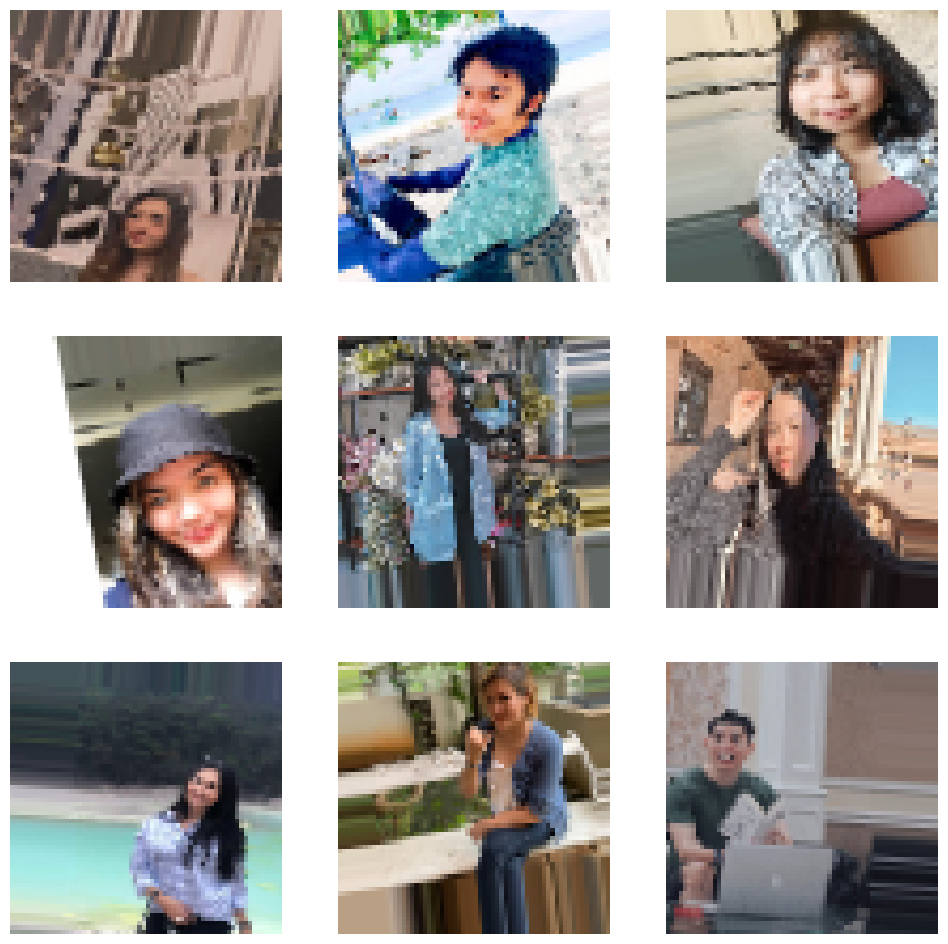

In [ ]:
# Visualisasi beberapa gambar dari training_set
for images, labels in training_set:
    plt.figure(figsize=(12, 12))
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])
        plt.axis('off')
    break
plt.show()


In [ ]:
# Membuat model
model = Sequential()

model.add(Conv2D(32, (3, 3), input_shape=(64, 64, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Flatten())
model.add(Dense(units=256, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(units=1, activation='sigmoid'))

# Compile model dengan optimizer Adam
model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
history = model.fit(
    training_set,
    steps_per_epoch=len(training_set),
    epochs=50,  # Meningkatkan jumlah epoch
    validation_data=test_set,
    validation_steps=len(test_set)
)


Epoch 1/50
138/138 [==============================] - 2121s 15s/step - loss: 0.6851 - accuracy: 0.5728 - val_loss: 0.6650 - val_accuracy: 0.6316
Epoch 2/50
138/138 [==============================] - 111s 810ms/step - loss: 0.6744 - accuracy: 0.5755 - val_loss: 0.6385 - val_accuracy: 0.6433
Epoch 3/50
138/138 [==============================] - 91s 656ms/step - loss: 0.6727 - accuracy: 0.5918 - val_loss: 0.6613 - val_accuracy: 0.6316
Epoch 4/50
138/138 [==============================] - 108s 783ms/step - loss: 0.6552 - accuracy: 0.6109 - val_loss: 0.6309 - val_accuracy: 0.6363
Epoch 5/50
138/138 [==============================] - 110s 801ms/step - loss: 0.6471 - accuracy: 0.6218 - val_loss: 0.6964 - val_accuracy: 0.4982
Epoch 6/50
138/138 [==============================] - 91s 660ms/step - loss: 0.6354 - accuracy: 0.6340 - val_loss: 0.6450 - val_accuracy: 0.6199
Epoch 7/50
138/138 [==============================] - 90s 656ms/step - loss: 0.6060 - accuracy: 0.6780 - val_loss: 0.6180 - val

54/54 [==============================] - 21s 382ms/step - loss: 0.3566 - accuracy: 0.8468
Test Accuracy: 84.68%


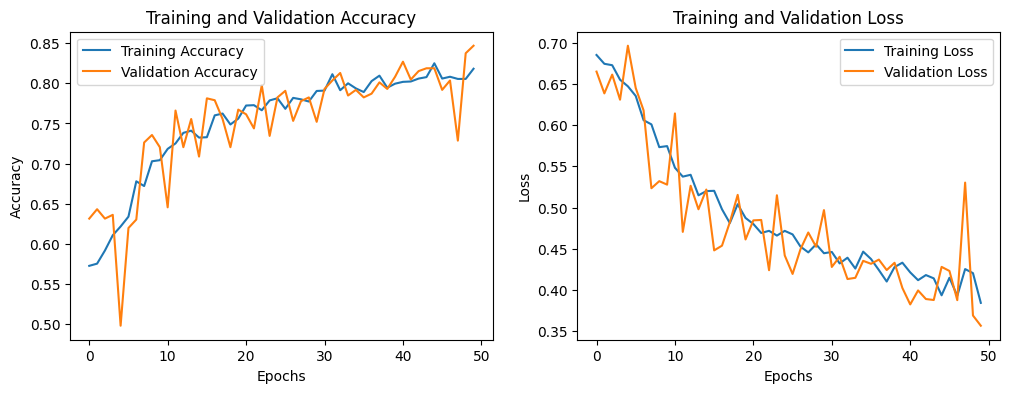

In [ ]:
# Evaluasi model pada data testing
test_loss, test_accuracy = model.evaluate(test_set)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Visualisasi kurva akurasi dan loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')

plt.show()


In [ ]:
# Menampilkan ringkasan arsitektur model
model.summary()


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_1 (Conv2D)           (None, 62, 62, 32)        896       
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 31, 31, 32)        0         
 g2D)                                                            
                                                                 
 dropout (Dropout)           (None, 31, 31, 32)        0         
                                                                 
 conv2d_2 (Conv2D)           (None, 29, 29, 64)        18496     
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 14, 14, 64)        0         
 g2D)                                                            
                                                                 
 dropout_1 (Dropout)         (None, 14, 14, 64)       

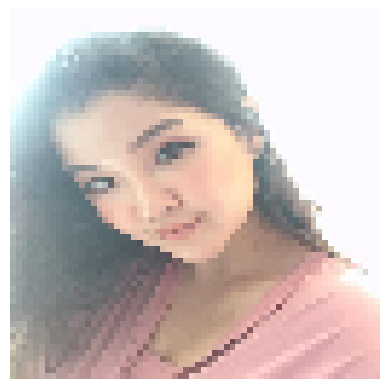

1/1 [==============================] - 0s 53ms/step
Hasil Prediksi: Female


In [ ]:

# Ambil gambar pertama dari dataset testing
test_image, test_label = test_set[0]  # Mengambil batch pertama dari test_set
image = test_image[0]  # Ambil gambar pertama dari batch

# Tampilkan gambar
plt.imshow(image)
plt.axis('off')
plt.show()

# Lakukan prediksi pada gambar tersebut
prediction = model.predict(np.expand_dims(image, axis=0))

# Interpretasi hasil prediksi
if prediction[0][0] > 0.5:
    result = 'Male'
else:
    result = 'Female'

print('Hasil Prediksi:', result)


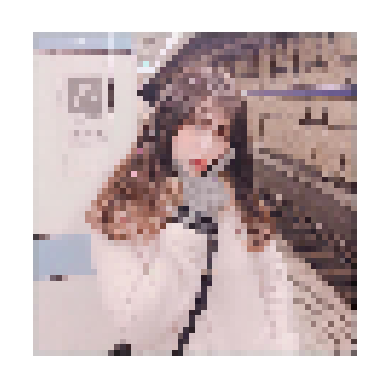

1/1 [==============================] - 0s 36ms/step
Hasil Prediksi: Female


In [ ]:
# Ambil gambar pertama dari dataset testing
test_image, test_label = test_set[3]  # Mengambil batch keempat dari test_set
image = test_image[3]  # Ambil gambar keempat dari batch

# Tampilkan gambar
plt.imshow(image)
plt.axis('off')
plt.show()

# Lakukan prediksi pada gambar tersebut
prediction = model.predict(np.expand_dims(image, axis=0))

# Interpretasi hasil prediksi
if prediction[0][0] > 0.5:
    result = 'Male'
else:
    result = 'Female'

print('Hasil Prediksi:', result)

1/1 [==============================] - 0s 79ms/step


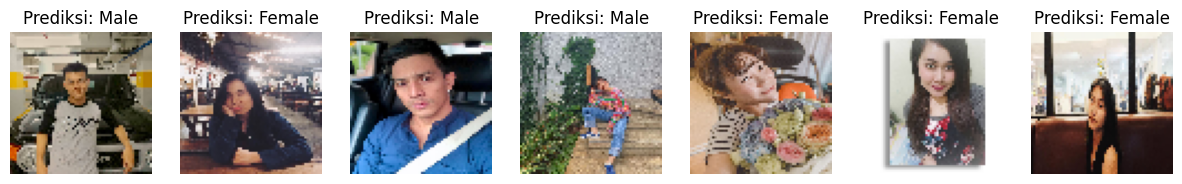

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Jumlah gambar yang ingin ditampilkan
num_images = 7

# Ambil beberapa gambar dari dataset testing
images, labels = test_set.next()

# Melakukan prediksi pada setiap gambar
predictions = model.predict(images)

# Menampilkan setiap gambar beserta hasil prediksinya
plt.figure(figsize=(15, 10))
for i in range(num_images):
    plt.subplot(1, num_images, i+1)
    plt.imshow(images[i])
    plt.title('Prediksi: {}'.format('Male' if predictions[i][0] > 0.5 else 'Female'))
    plt.axis('off')

plt.show()
